In [2]:
%pip install pandas scipy scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
data = {
    'Month': pd.date_range(
        start='2025-01-01', periods=12, freq='MS'
    ),
    'Sales': [
        12000, 13500, 12800, 15000,
        16000, 15500, 17500, 18000,
        17000, 19500, 21000, 23000
    ]
}

df = pd.DataFrame(data)

print(df)

        Month  Sales
0  2025-01-01  12000
1  2025-02-01  13500
2  2025-03-01  12800
3  2025-04-01  15000
4  2025-05-01  16000
5  2025-06-01  15500
6  2025-07-01  17500
7  2025-08-01  18000
8  2025-09-01  17000
9  2025-10-01  19500
10 2025-11-01  21000
11 2025-12-01  23000


In [5]:
df = df.drop_duplicates()
df = df.dropna(subset=['Sales'])

print("Cleaned Sales Data:")
print(df)

Cleaned Sales Data:
        Month  Sales
0  2025-01-01  12000
1  2025-02-01  13500
2  2025-03-01  12800
3  2025-04-01  15000
4  2025-05-01  16000
5  2025-06-01  15500
6  2025-07-01  17500
7  2025-08-01  18000
8  2025-09-01  17000
9  2025-10-01  19500
10 2025-11-01  21000
11 2025-12-01  23000


In [6]:
correlation, p_value = stats.pearsonr(
    range(1, 13), df['Sales']
)

print("Sales Correlation:", round(correlation, 3))
print("P-value:", round(p_value, 4))

Sales Correlation: 0.964
P-value: 0.0


In [7]:
df['Month_Number'] = np.arange(1, 13)

X = df[['Month_Number']]
y = df['Sales']

model = LinearRegression()
model.fit(X, y)

future = pd.DataFrame({
    'Month_Number': [13, 14, 15]
})

predictions = model.predict(future)

print("Future Sales Predictions:")

for month, sales in zip(
    ['Jan 2026', 'Feb 2026', 'Mar 2026'],
    predictions
):
    print(month, ":", round(sales, 2))

Future Sales Predictions:
Jan 2026 : 22492.42
Feb 2026 : 23378.44
Mar 2026 : 24264.45


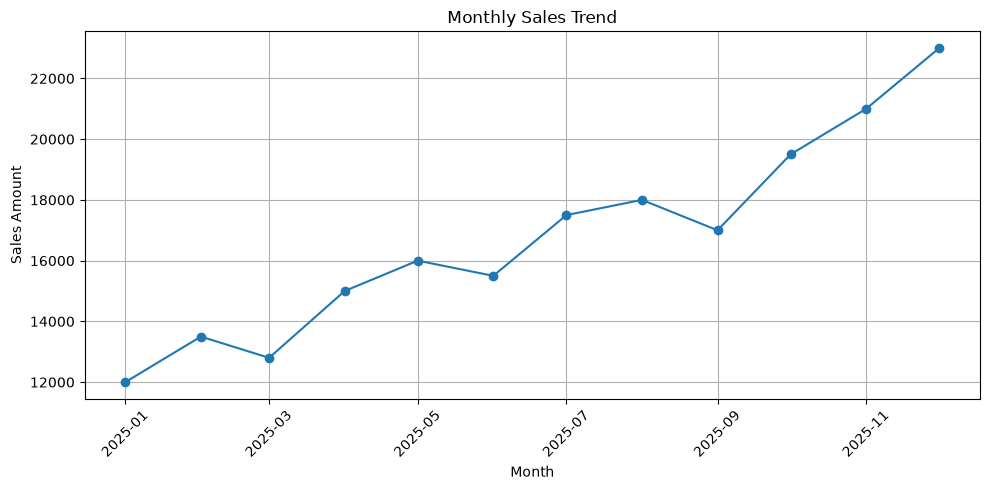

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(df['Month'], df['Sales'], marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales Amount')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

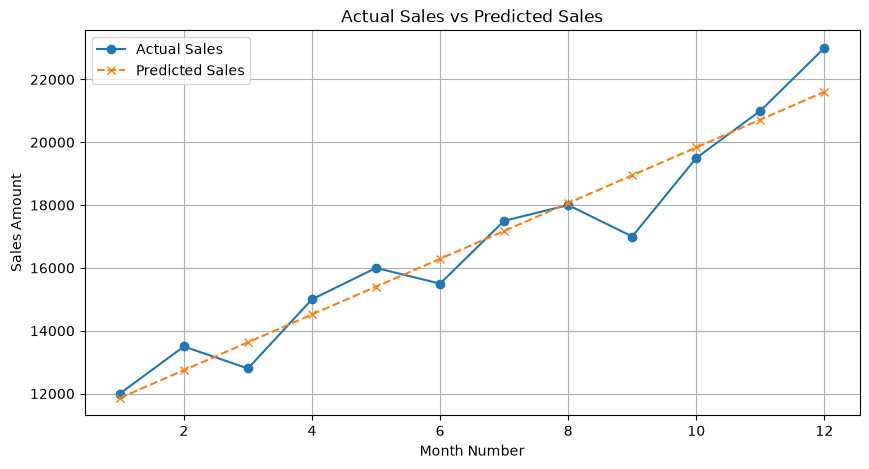

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(df['Month_Number'], y,
         marker='o', label='Actual Sales')

plt.plot(df['Month_Number'], model.predict(X),
         linestyle='--', marker='x',
         label='Predicted Sales')

plt.title('Actual Sales vs Predicted Sales')
plt.xlabel('Month Number')
plt.ylabel('Sales Amount')
plt.legend()
plt.grid(True)
plt.show()

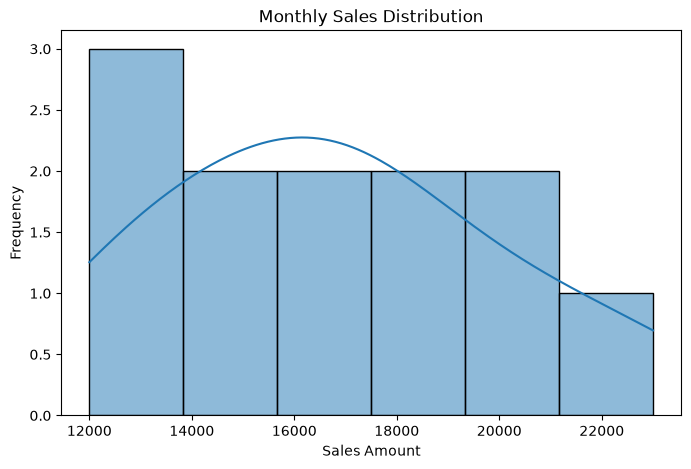

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(df['Sales'], bins=6, kde=True)

plt.title('Monthly Sales Distribution')
plt.xlabel('Sales Amount')
plt.ylabel('Frequency')

plt.show()

In [11]:
predicted_sales = model.predict(X)

print("Mean Absolute Error:",
      round(mean_absolute_error(y, predicted_sales), 2))

print("R2 Score:",
      round(r2_score(y, predicted_sales), 3))

Mean Absolute Error: 661.29
R2 Score: 0.929


In [12]:
print("SALES FORECASTING DASHBOARD")
print("-" * 35)

for month, sales in zip(
    ['January 2026', 'February 2026', 'March 2026'],
    predictions
):
    print(f"{month}: {sales:.2f}")

print("-" * 35)
print("Forecast completed successfully!")

SALES FORECASTING DASHBOARD
-----------------------------------
January 2026: 22492.42
February 2026: 23378.44
March 2026: 24264.45
-----------------------------------
Forecast completed successfully!
